In [1]:
%pip install scikit-learn

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



from sklearn.cluster import KMeans

import warnings
warnings.filterwarnings('ignore')

In [6]:
df = pd.read_csv('Instagram visits clustering.csv')
df.head()

,User ID,Instagram visit score,Spending_rank(0 to 100)
0,0,63,24.050708
1,1,61,25.223290
2,2,104,18.528245
3,3,82,86.890232
4,4,14,31.492397


In [7]:
df.describe()

,User ID,Instagram visit score,Spending_rank(0 to 100)
count,2600.000000,2600.000000,2600.000000
mean,1299.500000,63.323462,42.848408
std,750.699674,26.579760,28.758349
min,0.000000,5.000000,0.940709
25%,649.750000,38.000000,19.452098
50%,1299.500000,72.000000,28.013082
75%,1949.250000,86.000000,72.116945
max,2599.000000,118.000000,107.349821


In [8]:
df.isnull().sum() #check for null values

,0
User ID,0
Instagram visit score,0
Spending_rank(0 to 100),0


In [10]:
from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Fit and transform your raw feature data
X = df[['Instagram visit score' , 'Spending_rank(0 to 100)']].iloc[: , :].values
X_scaled = scaler.fit_transform(X)
df_scaled = pd.DataFrame(X_scaled, columns=['Instagram visit score', 'Spending_rank(0 to 100)'])

In [29]:
inertia = []
for n in range(1 , 11):
    algorithm = (KMeans(n_clusters = n ,init='k-means++', n_init = 10 ,max_iter=300,
                        tol=0.0001,  random_state= 111  , algorithm='elkan') )
    algorithm.fit(X_scaled)
    inertia.append(algorithm.inertia_)

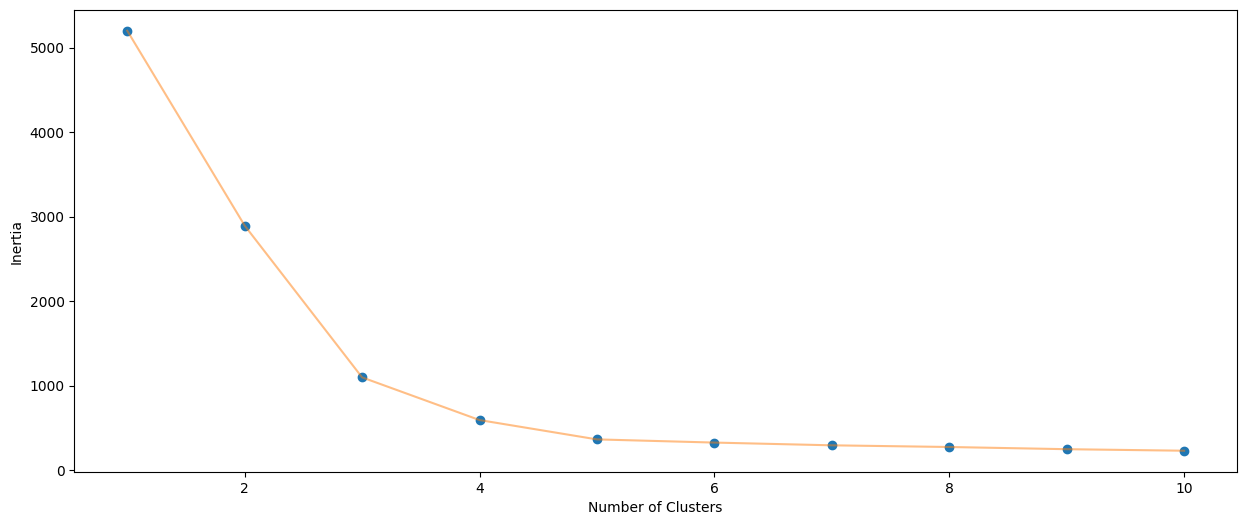

In [30]:
plt.figure(1 , figsize = (15 ,6))
plt.plot(np.arange(1 , 11) , inertia , 'o')
plt.plot(np.arange(1 , 11) , inertia , '-' , alpha = 0.5)
plt.xlabel('Number of Clusters') , plt.ylabel('Inertia')
plt.show()

In [31]:
algorithm = (KMeans(n_clusters = 5 ,init='k-means++', n_init = 10 ,max_iter=300,
                        tol=0.0001,  random_state= 111  , algorithm='elkan') )
algorithm.fit(X_scaled)
labels2 = algorithm.labels_
centroids2 = algorithm.cluster_centers_

In [32]:
h = 0.02
x_min, x_max = X_scaled[:, 0].min() - 1, X_scaled[:, 0].max() + 1
y_min, y_max = X_scaled[:, 1].min() - 1, X_scaled[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
Z2 = algorithm.predict(np.c_[xx.ravel(), yy.ravel()])

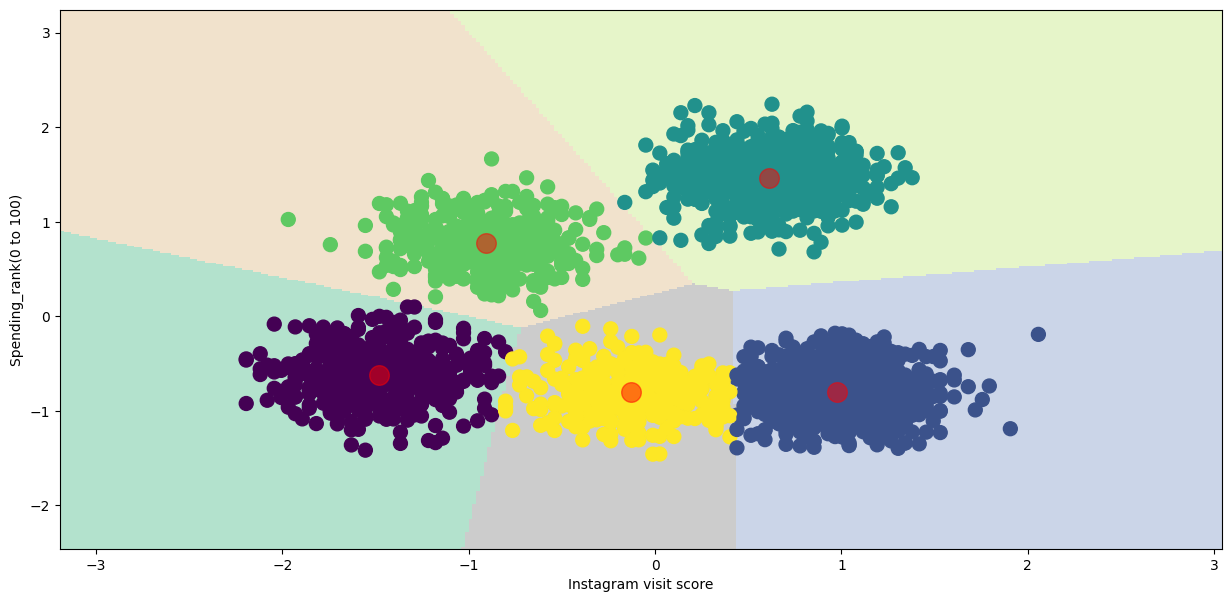

In [33]:
plt.figure(1 , figsize = (15 , 7) )
plt.clf()
Z2 = Z2.reshape(xx.shape)
plt.imshow(Z2 , interpolation='nearest',
           extent=(xx.min(), xx.max(), yy.min(), yy.max()),
           cmap = plt.cm.Pastel2, aspect = 'auto', origin='lower')

plt.scatter( x = 'Instagram visit score' ,y = 'Spending_rank(0 to 100)' , data = df_scaled , c = labels2 ,
            s = 100 )
plt.scatter(x = centroids2[: , 0] , y =  centroids2[: , 1] , s = 200 , c = 'red' , alpha = 0.5)
plt.ylabel('Spending_rank(0 to 100)') , plt.xlabel('Instagram visit score')
plt.show()

When deciding how many clusters to use, there is a big elbow in the graph at the 3 cluster mark and a small elbow at the 5 mark. It seems like 3 would be the ideal cluster, however, after looking at the graph, there are 5 obvious clusters in the graphed data. Due to these facts, I chose to do 5 clusters.

Based on the data, there are three groupings of people who are under the average time spent per visit. One of these groups looks at Instagram very few times, one an average amout of times, and one an above average amount of times. These 3 clusters are all at a similar level of time spent, about -0.5 units below average. The other 2 clusters are above the average about of time spent per visit. One lies at about 1 unit above average in time spent and 1 unit below average in number of visits. The other one sits at about 1.5 units above average for time spent per visit and 0.75 units above average on number of visits.

Based on this data, there are fairly well defined groups of people based on how many times they visit instagram and how long they spend per visit. There is definatly a group that is above average in both of these categories, indicating an addiction. There are also groups who are above average in one of the two categories but below average in the other. I would argue that either of these groups is at least at risk of having an addiction to the app. It would depend on how an addiction is defined by the researcher in charge.